# Lights Out · Phase 3 forecast scorecard

**Question 8:** how many MW will be cut in each hour of the next 7 days?
**Question 5:** can cuts be forecast at all, and how far ahead?

Every forecast is made at midnight using only data from before midnight, then checked against what happened.
Four test windows; for each one the model is trained only on data before the window starts.
Built by `04_model/forecast.py`.

In [1]:
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
con = duckdb.connect('../01_data/processed/lights_out.duckdb', read_only=True); q = lambda s: con.sql(s).df()
pd.set_option('display.width', 160)
CARD, GREEN, GREEN2, OCHRE, TOMATO, SLATE, INK, GRID = '#F7F1E6','#1D4A35','#3B8A60','#B87318','#F2462E','#7D8D99','#16382A','#E6DCC8'
plt.rcParams.update({'figure.facecolor': CARD, 'axes.facecolor': CARD, 'axes.edgecolor': GRID, 'axes.labelcolor': INK,
    'xtick.color': '#4F5E52', 'ytick.color': '#4F5E52', 'axes.grid': True, 'grid.color': GRID, 'axes.spines.top': False,
    'axes.spines.right': False, 'font.size': 10.5, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlecolor': GREEN,
    'axes.titlelocation': 'left', 'figure.dpi': 110})
COL = {'Same hour last week': SLATE, '4-week hour average': OCHRE, 'LightGBM model': GREEN2, 'Blend (final forecast)': TOMATO}

## The scorecard (all four windows, 27,622 hours)

In [2]:
sc = q("SELECT * FROM model.scorecard_all").set_index('method')
show = sc[['MAE (MW)', 'WAPE', '500 MW+ hours caught', 'false alarms']].copy()
show['MAE (MW)'] = show['MAE (MW)'].round(0).astype(int)
for c in ['WAPE', '500 MW+ hours caught', 'false alarms']: show[c] = show[c].map('{:.0%}'.format)
print(f"80% range held the actual value {sc.range_coverage_80.iloc[0]:.0%} of the time (built from these same backtest errors, by how heavy cuts were over the past week and how far ahead).")
show

80% range held the actual value 81% of the time (built from these same backtest errors, by how heavy cuts were over the past week and how far ahead).


,MAE (MW),WAPE,500 MW+ hours caught,false alarms
method,,,,
Same hour last week,735,90%,60%,40%
4-week hour average,648,79%,75%,49%
LightGBM model,650,79%,63%,45%
Blend (final forecast),623,76%,82%,45%


**How to read it.** MAE is the average miss in MW per hour. "500 MW+ hours caught" is the share of hours with a
significant cut that the forecast also flagged; "false alarms" is the share of flagged hours that turned out fine.

The planner's 4-week average is a strong rule of thumb. The model alone only matches it; **blending the two** is
best: the smallest miss (about 4% below the 4-week average) and **82% of significant-cut hours caught**.

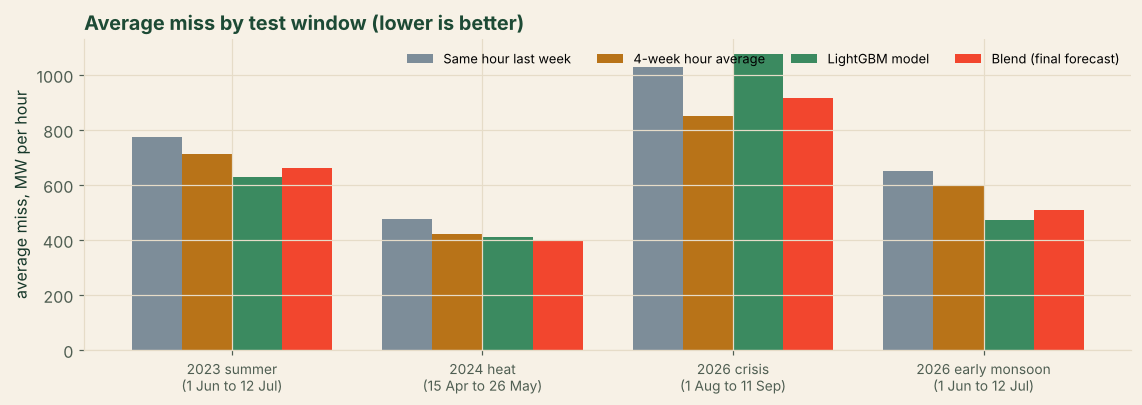

method,Same hour last week,4-week hour average,LightGBM model,Blend (final forecast)
window,,,,
2023 summer (1 Jun to 12 Jul),776,714,630,663
2024 heat (15 Apr to 26 May),476,420,410,397
2026 crisis (1 Aug to 11 Sep),1029,852,1076,915
2026 early monsoon (1 Jun to 12 Jul),651,598,471,510


In [3]:
w = q("SELECT \"window\", method, \"MAE (MW)\" AS mae FROM model.scorecard").pivot(index='window', columns='method', values='mae')
w = w[list(COL)]
fig, ax = plt.subplots(figsize=(10.5, 3.8)); x = np.arange(len(w)); bw = .2
for i, m in enumerate(w.columns): ax.bar(x + (i - 1.5) * bw, w[m], bw, color=COL[m], label=m)
ax.set_xticks(x, [s.replace(' (', '\n(') for s in w.index], fontsize=9); ax.set_ylabel('average miss, MW per hour')
ax.set_title('Average miss by test window (lower is better)'); ax.legend(frameon=False, ncol=4, fontsize=8.5)
plt.tight_layout(); plt.show()
w.round(0).astype(int)

**The 2026 crisis is the exception.** From August to mid-September, cuts followed sudden supply shocks (the LNG
terminal fire on 21 July, the second terminal offline in August) that nothing in the grid's history could predict.
The plain 4-week pattern adapted fastest. This is the honest answer to question 5.

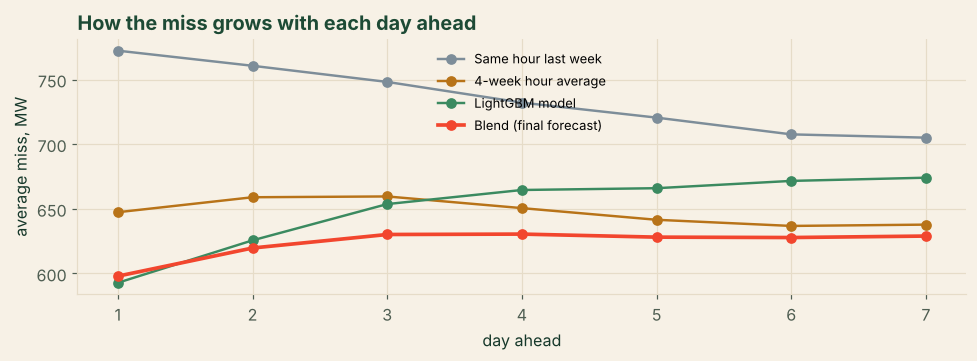

In [4]:
eh = q("SELECT * FROM model.error_by_horizon ORDER BY horizon_day").set_index('horizon_day')[list(COL)]
fig, ax = plt.subplots(figsize=(9, 3.4))
for m in eh.columns: ax.plot(eh.index + 1, eh[m], marker='o', color=COL[m], lw=2.4 if 'Blend' in m else 1.6, label=m)
ax.set_xlabel('day ahead'); ax.set_ylabel('average miss, MW'); ax.set_title('How the miss grows with each day ahead')
ax.legend(frameon=False, fontsize=8.5); plt.tight_layout(); plt.show()

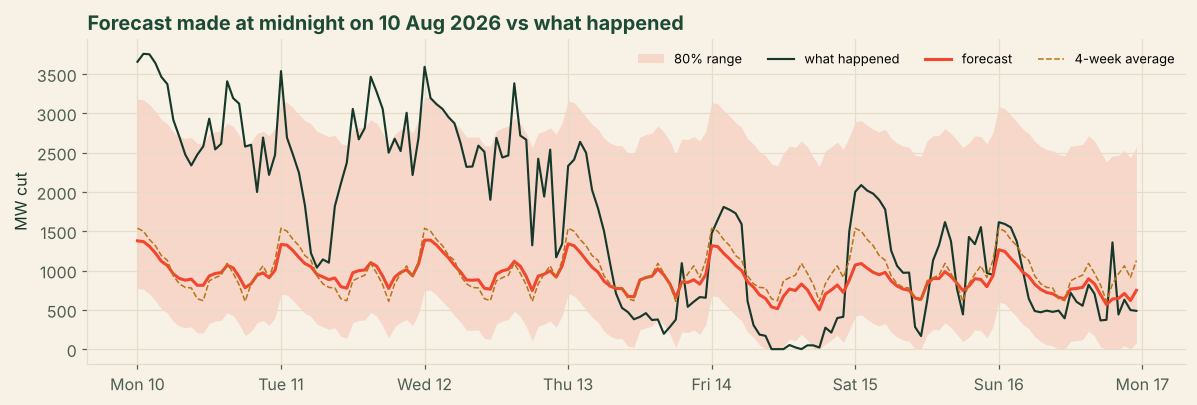

In [5]:
# One crisis week in detail: forecast made at midnight on 10 Aug 2026 (the year's peak day)
b = q("""SELECT ts, actual, blend, low_mw, high_mw, b_planner FROM model.backtest
         WHERE origin = DATE '2026-08-10' ORDER BY ts""")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(b.ts, b.low_mw, b.high_mw, color=TOMATO, alpha=.15, lw=0, label='80% range')
ax.plot(b.ts, b.actual, color=INK, lw=1.4, label='what happened'); ax.plot(b.ts, b.blend, color=TOMATO, lw=2, label='forecast')
ax.plot(b.ts, b.b_planner, color=OCHRE, lw=1, ls='--', label='4-week average')
ax.set_title('Forecast made at midnight on 10 Aug 2026 vs what happened'); ax.set_ylabel('MW cut')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %d')); ax.legend(frameon=False, ncol=4, fontsize=8.5)
plt.tight_layout(); plt.show()

## What drives the model

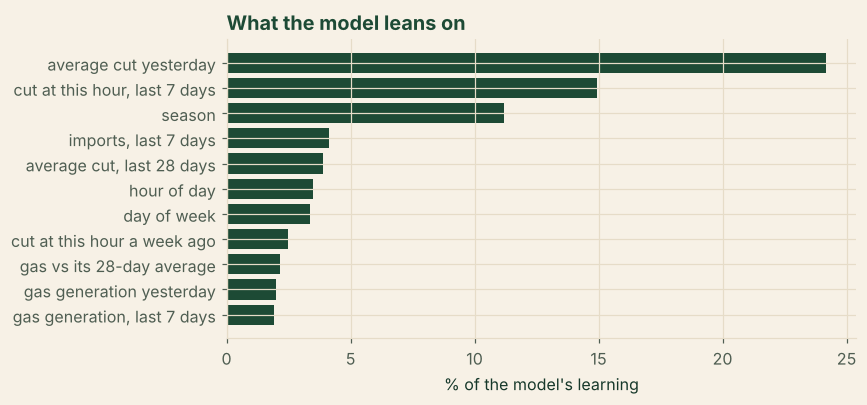

In [6]:
fi = q("SELECT feature, share FROM model.feature_importance ORDER BY share DESC LIMIT 12")
names = {'shed_same_hour_7d': 'cut at this hour, last 7 days', 'shed_7d_mean': 'average cut, last 7 days',
         'shed_last_week': 'cut at this hour a week ago', 'shed_1d_mean': 'average cut yesterday', 'hour': 'hour of day',
         'shed_28d_mean': 'average cut, last 28 days', 'shed_7d_max': 'biggest cut, last 7 days', 'shed_1d_max': 'biggest cut yesterday',
         'dem_same_hour_7d': 'demand at this hour, last 7 days', 'gas_1d': 'gas generation yesterday', 'gas_7d': 'gas generation, last 7 days',
         'gas_drop': 'gas vs its 28-day average', 'horizon_day': 'days ahead', 'dow': 'day of week', 'is_weekend': 'weekend', 'is_holiday': 'holiday', 'shed_7d_pct_hours': 'share of hours cut, last 7 days',
         'doy_sin': 'season', 'doy_cos': 'season', 'dem_7d_mean': 'average demand, last 7 days', 'oil_7d': 'oil generation, last 7 days',
         'coal_7d': 'coal generation, last 7 days', 'imports_7d': 'imports, last 7 days', 'month': 'month', 'shed_trend': 'cut trend, last 3 vs 4 days'}
fi['what'] = fi.feature.map(names).fillna(fi.feature)
fig, ax = plt.subplots(figsize=(8, 3.8)); ax.barh(fi.what[::-1], fi.share[::-1] * 100, color=GREEN)
ax.set_xlabel('% of the model\'s learning'); ax.set_title('What the model leans on'); plt.tight_layout(); plt.show()

## The next 7 days

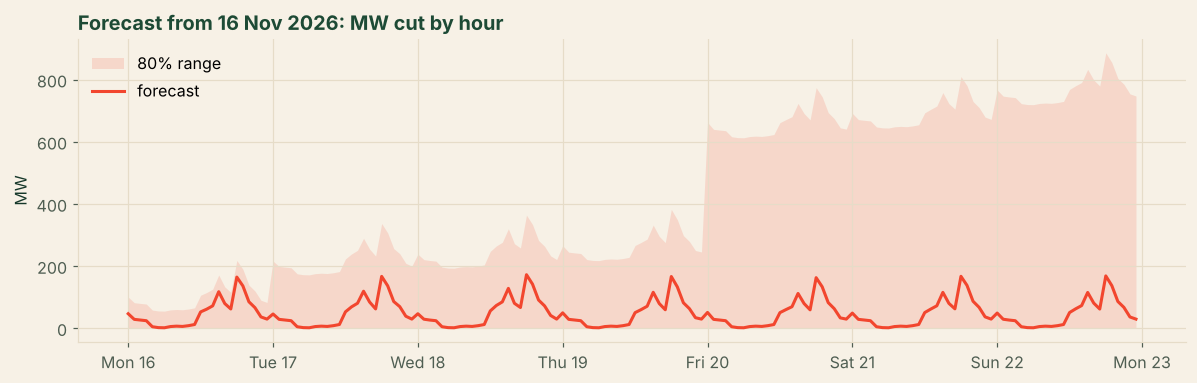

Total expected: 8.0 GWh; peak hour 172 MW.
Riskiest hours (share of the last 28 days with 500 MW+ cut at that hour):
                 ts  forecast_mw  cut_risk
2026-11-16 18:00:00   164.235446  0.214286
2026-11-19 18:00:00   166.027147  0.214286
2026-11-22 18:00:00   168.058984  0.214286
2026-11-21 18:00:00   166.728537  0.214286
2026-11-20 18:00:00   162.349646  0.214286


In [7]:
fc = q("SELECT * FROM model.forecast_next_week ORDER BY ts")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(fc.ts, fc.low_mw, fc.high_mw, color=TOMATO, alpha=.15, lw=0, label='80% range')
ax.plot(fc.ts, fc.forecast_mw, color=TOMATO, lw=2, label='forecast')
ax.set_title(f"Forecast from {fc.origin.iloc[0]:%d %b %Y}: MW cut by hour"); ax.set_ylabel('MW')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %d')); ax.legend(frameon=False); plt.tight_layout(); plt.show()
top = fc.sort_values('cut_risk', ascending=False).head(5)[['ts', 'forecast_mw', 'cut_risk']]
print(f"Total expected: {fc.forecast_mw.sum()/1000:,.1f} GWh; peak hour {fc.forecast_mw.max():,.0f} MW.")
print('Riskiest hours (share of the last 28 days with 500 MW+ cut at that hour):'); print(top.to_string(index=False))

**About the range.** It comes from the real misses in the test weeks, picked by how heavy cuts were over the
past 7 days and by day ahead, and it only widens as the days go on. In a quiet week it stays narrow for the first
four days, then opens up: in the quiet test weeks, cuts sometimes came back within 5 to 7 days. All test weeks were
in summer, so in winter this range is on the cautious side.

## Answers

**Q8. How much next week?** The forecast above, refreshed each time the collector and `forecast.py` run. On past
test weeks it missed by about 620 MW per hour on average and caught 82% of the hours with a significant cut.

**Q5. Can cuts be forecast?** Partly. The grid's own history adds a little to the recent pattern (about 4%, most on
the first two days), and bad days do run in streaks. But in a supply shock the history cannot see what is coming:
in the 2026 crisis the simple 4-week pattern did best. A reliable outlook needs the grid's supply plan (gas allocation,
LNG cargo schedule, planned plant outages), which only the load dispatch centre holds. That is the basis for the
"publish a 7-day outlook" suggestion: the people who hold the plan are the ones who can forecast well.